# Setup

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import json

## IMPORTS
import os
from typing import Literal

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import KDTree, cKDTree
from shapely.geometry import Point, box
from shapely.ops import unary_union

import src.data_filepaths as data_filepaths
import src.utils.loaders as loaders
import src.utils.vis.colors_utils as colors_utils
from src.utils.df_tools import map_values_b_to_bp, shuffle_df
from src.utils.loaders import (
    process_loaded_building_df,
)
from src.utils.vis.map import CategoricalColorMap, MapExplorer
from src.utils.vis.map_special import (
    build_map_building_basic,
    build_map_point_floorspace_demand_type,
    build_map_point_numeric_and_category,
)

# configs
sns.set_theme()

## Load

In [2]:
ALLOW_EXPORT = False

In [3]:
b_gdf = process_loaded_building_df(gpd.read_parquet(data_filepaths.OVERTURE_BUILDING))
bp_gdf = process_loaded_building_df(
    gpd.read_parquet(data_filepaths.OVERTURE_BUILDING_PART)
)

osm_landuse_gdf = loaders.load_osm_landuse_1_geojson_to_gdf(data_filepaths.OSM_landuse)
mp_landuse_gdf = loaders.load_masterplan_landuse_geojson_to_gdf(
    data_filepaths.MASTERPLAN_LANDUSE
)

# Process

## Remove Buildings

Derivative of earlier code; I should really have this code somewhere else..?

In [4]:
def merge_with_landuse(
    b_gdf: gpd.GeoDataFrame,
    # bp_gdf: gpd.GeoDataFrame,
):
    """
    Returns `buildings_osm_merge`, `buildings_mp_merge`
    """

    buildings_osm_merge = gpd.sjoin(
        b_gdf[["centroid"]].set_geometry("centroid"),
        osm_landuse_gdf,
        how="left",
        predicate="intersects",
    )
    # deduplicate buildings having more than one associated plot/area
    buildings_osm_merge = buildings_osm_merge[
        ~buildings_osm_merge.index.duplicated(keep="first")
    ]

    buildings_osm_merge = buildings_osm_merge.drop(columns="index_right")

    buildings_mp_merge = gpd.sjoin(
        b_gdf[["centroid"]].set_geometry("centroid"),
        mp_landuse_gdf,
        how="left",
        predicate="intersects",
    )
    # deduplicate buildings having more than one associated plot/area
    buildings_mp_merge = buildings_mp_merge[
        ~buildings_mp_merge.index.duplicated(keep="first")
    ]

    buildings_mp_merge["landuse"].value_counts(dropna=False)

    # fix bool columns, because pandas reasons...?
    buildings_mp_merge["is_sdp"] = buildings_mp_merge["is_sdp"].astype(bool)
    buildings_mp_merge["is_landed"] = buildings_mp_merge["is_landed"].astype(bool)

    # no assigning to b_gdf is being done
    return buildings_osm_merge, buildings_mp_merge


def preprocess_remove_buildings_modified(
    b_gdf: gpd.GeoDataFrame,
    bp_gdf: gpd.GeoDataFrame,
    buildings_osm_merge,  # [landuse]
    buildings_mp_merge,  # [landuse, gpr]
    mp_landuse_gdf,
    building_size_thresholds={
        "OSM": 60,  # this number is quite high, but for demand I think it's fine
        "Google": 400,
        "Microsoft": 400,
    },
    mp_zone_coverage_threshold=0.06,
):
    """
    THIS CODE IS MODIFIED SPECIFICALLY FOR GENERATING VISUAL BUILDINGS. This function docstring however, has not been
    modified.

    Removes buildings from `b_gdf`/`bp_gdf` (mapped from `b_gdf`) and returns them with removal reasons added,
    but no removal done. Creates new columns `removal_reason`, `is_removed` for both `b_gdf` and `bp_gdf`.

    There are 10 removal reasons:
    * `Landuse-OSM`: This removes the OSM landuses:
        * `construction` - self explanatory
        * `landuse=industrial, industrial=port` - to complement the port Masterplan zonings, to achieve a more
        complete removal of those buildings. This is specifically for areas around Keppel Harbour, that have long
        been designated for future development, but as of writing in 2026 still houses active port facilities.
    * `Buildingtype-Overture` The following Overture building subtypes and classes are removed:
        * Subtypes: `transportation` (includes remaining transportation buildings, and crucially, `parking`),
            `outbuilding`.
        * Classes: `roof`, `pavilion`, `hut`, `shed`, `carport`, `bridge_structure`.
    * `Size-OSM`, `Size-Google`, `Size-Microsoft`: Buildings under a specified footprint size threshold are removed.
        The threshold will be higher for the ML-derived datasets from Google/Microsoft.
        This is specified in the parameter `building_size_thresholds`.
    * `Landuse-MP`: The following **non-demand** Masterplan zoning types are removed:
        `HEALTH & MEDICAL CARE`, `EDUCATIONAL INSTITUTION`, `PLACE OF WORSHIP`, `CIVIC & COMMUNITY INSTITUTION`,
        `PARK`, `BEACH AREA`, `SPORTS & RECREATION`, `WATERBODY`, `ROAD`, `TRANSPORT FACILITIES`,
        `MASS RAPID TRANSIT`, `LIGHT RAPID TRANSIT`, `UTILITY`, `CEMETERY`, `PORT / AIRPORT`, `SPECIAL USE`.
        * `RESERVE SITE` and `OPEN SPACE` are not removed and processed in a later step.
        * In the future, `UTILITY` should be processed as well, but that requires more specific conditions to
        exclude small-medium sized utility areas like substations, while retaining large utility facilities that have
        worker prescences.
    * `Landuse-MP_coverage`: Removes buildings in zones with less than the `mp_zone_coverage_threshold` parameter.
        Note that this uses the original set of buildings (i.e. unremoved buildings).
        Default threshold is set to 0.06, with 0.08 being a rough maximum before false positives start
        getting removed.
        * There is an exception for buildings in OSM `landuse=residential`. As certain areas containing bungalows
            (e.g. Mt Pleasant, Alexandria Pk) have so incredibly low density, they end up being false positives. This
            exception is in place for those buildings. If an area *is* tagged residential on OSM, that is likely
            correct and desirable anyway.
    * `Bbox-removed-areas`: These are custom defined areas where buildings are manually removed.
        They are typically areas slated for (or currently ongoing) future development,
        but currently have enough credible non-demand buildings in
        the zone to not be removed in earlier steps.
    * `Non-OSM_MP-res`: Non-OSM (i.e. ML-derived buildings) in residential plots. The vast majority of the time,
        these buildings are just construction or temporary buildings that have been picked up by these image
        recognition models, and OSM data is more than good enough on its own.
    * `Building_ID`: Specific `building_id`s that were specified for removal


    Future improvements/additions:
    * PORT/AIRPORT (both OSM and MP check): take only OSM buildings
    * CEMETERY - take OSM only
    """

    b_gdf = b_gdf.copy()
    bp_gdf = bp_gdf.copy()

    BUILDING_ID_TO_REMOVE = []

    # clean removals that have no other condition
    MP_LANDUSES_TO_REMOVE = [
        # "HEALTH & MEDICAL CARE",
        # "EDUCATIONAL INSTITUTION",
        # "PLACE OF WORSHIP",
        # "CIVIC & COMMUNITY INSTITUTION",
        # "PARK",
        # "BEACH AREA",
        # "SPORTS & RECREATION",
        "WATERBODY",
        "ROAD",
        "TRANSPORT FACILITIES",
        "MASS RAPID TRANSIT",
        "LIGHT RAPID TRANSIT",
        # "UTILITY",
        "CEMETERY",
        # "PORT / AIRPORT",
        # "SPECIAL USE",
        # "RESERVE SITE",
        # "OPEN SPACE",
    ]
    MP_LANDUSE_REMOVAL_DICT = {
        landuse: "Landuse-MP" for landuse in MP_LANDUSES_TO_REMOVE
    }
    OVERTURE_REMOVAL_SUBTYPES = ["outbuilding"]
    OVERTURE_REMOVAL_CLASSES = [
        "roof",
        # "pavilion",
        "hut",
        "shed",
        "carport",
        "bridge_structure",
        # "transportation", # this removes bus stations and the like. But it also reports Changi T4
    ]

    b_gdf[["mp_landuse"]] = buildings_mp_merge[["landuse"]]
    b_gdf[["mp_gpr"]] = buildings_mp_merge[["gpr"]]
    b_gdf[["mp_OBJECTID"]] = buildings_mp_merge[["OBJECTID"]]

    # for removing buildings in areas with less than MP_COVERAGE_THRESHOLD occupancy
    # first calculate areas of a zone
    # this makes an assumption that building footprints are fully inside their zone
    # which is not true. but I can't be bothered
    b_mp_covered = b_gdf.groupby("mp_OBJECTID")["area"].sum()
    mp_area = mp_landuse_gdf.geometry.area

    ###################################

    REMOVE_REASONS_DICT = {
        "Landuse-OSM": (buildings_osm_merge["landuse"] == "construction"),
        "Buildingtype-Overture": (b_gdf["subtype"].isin(OVERTURE_REMOVAL_SUBTYPES))
        | (b_gdf["class"].isin(OVERTURE_REMOVAL_CLASSES)),
        "Size-OSM": (b_gdf["src_dataset_label"] == "OpenStreetMap")
        & (b_gdf["area"] < building_size_thresholds["OSM"]),
        "Size-Google": (b_gdf["src_dataset_label"] == "Google Open Buildings")
        & (b_gdf["area"] < building_size_thresholds["Google"]),
        "Size-Microsoft": (b_gdf["src_dataset_label"] == "Microsoft ML Buildings")
        & (b_gdf["area"] < building_size_thresholds["Microsoft"]),
        "Landuse-MP": buildings_mp_merge[
            "landuse"
        ].isna(),  # remove NaNs here, about 130 of them
        "NonOSM_Specific_MP": (
            (b_gdf["src_dataset_label"] != "OpenStreetMap")
            & buildings_mp_merge["landuse"].isin(["PORT / AIRPORT", "CEMETERY"])
        ),
        "Building_ID": buildings_mp_merge.index.isin(BUILDING_ID_TO_REMOVE),
    }

    # now asasign all reasons at once
    b_gdf["removal_reason"] = np.select(
        list(REMOVE_REASONS_DICT.values()),
        list(REMOVE_REASONS_DICT.keys()),
        default=None,
    )

    # ALSO Remove LANDUSE-MP ones
    # apply without overwriting non-matches
    b_gdf["removal_reason"] = (
        buildings_mp_merge["landuse"]
        .map(MP_LANDUSE_REMOVAL_DICT)
        .fillna(b_gdf["removal_reason"])
    )

    map_values_b_to_bp(b_gdf, bp_gdf, "removal_reason", "removal_reason")

    print(b_gdf["removal_reason"].value_counts(dropna=False))

    # create boolean removed columns
    b_gdf["is_removed"] = ~b_gdf["removal_reason"].isna()
    bp_gdf["is_removed"] = ~bp_gdf["removal_reason"].isna()

    return b_gdf, bp_gdf

In [5]:
buildings_osm_merge, buildings_mp_merge = merge_with_landuse(b_gdf)

b_gdf1, bp_gdf1 = preprocess_remove_buildings_modified(
    b_gdf,
    bp_gdf,
    buildings_osm_merge,
    buildings_mp_merge,
    mp_landuse_gdf,
    building_size_thresholds={
        "OSM": 35, 
        "Google": 3000,
        "Microsoft": 3000,
    }
)

removal_reason
NaN                      120500
Size-Google               72331
Size-Microsoft            26164
Landuse-MP                 8230
Landuse-OSM                5863
Size-OSM                   1402
Buildingtype-Overture      1204
NonOSM_Specific_MP           35
Name: count, dtype: int64


In [6]:
mapper = MapExplorer(
    b_gdf1,
    bp_gdf1,
    # enable_debug_mode=True,
)
mapper.build_configurable(["removal_reason"], title="Buildings")

id
396eb35f-2fd0-4a23-bd73-c721c53ca662    6.0
db49e9d4-75d4-4c2c-8fd4-5e518014c335    6.0
8199239e-970c-4ef7-b6a5-58c55a617322    6.0
de9fee83-628e-4704-8681-0b2b1116e0a0    6.0
dcd42c50-9fa6-4edf-ba7c-35a98dd45712    6.0
Name: height_calc, dtype: float64


### Readd Some Buildings

In future this could include setting MRT stations to be removed from collision (the index) but still visible

It would require setting some extra parameters though.

In terms of transport-related buildings, this would be:

- all mp_landuse=TRANSPORT FACILITIES, with a minimum size - these will be depot buildings
- all class=train_station - though you start to have to deal with underground buildings that weren't correctly tagged...

Ignore for the time being, since whether or not this is necessary is still up in the air.

### Handle Removals

Actually executes the removals based on column `is_removed`

In [7]:
b_gdf_rmv = b_gdf1[~b_gdf1["is_removed"]].drop(columns=["is_removed", "removal_reason"])
bp_gdf_rmv = bp_gdf1[~bp_gdf1["is_removed"]].drop(
    columns=["is_removed", "removal_reason"]
)

print(
    f"{len(b_gdf1) - len(b_gdf_rmv)}/{len(b_gdf1)} buildings removed: "
    + f"{((len(b_gdf1) - len(b_gdf_rmv)) / len(b_gdf1) * 100):.3f}%"
)
print(
    f"{len(bp_gdf1) - len(bp_gdf_rmv)}/{len(bp_gdf1)} building parts removed: "
    + f"{((len(bp_gdf1) - len(bp_gdf_rmv)) / len(bp_gdf1) * 100):.3f}%"
)

115229/235729 buildings removed: 48.882%
948/8230 building parts removed: 11.519%


## Give Proper Heights

based on `FLOOR_HEIGHTS` dict above

In [8]:
from src.map_processing.code.buildings import (
    assign_height_from_floors,
    assign_min_height_from_min_floor,
)

b_gdf2, bp_gdf2 = assign_height_from_floors(
    b_gdf_rmv, bp_gdf_rmv, default_bldg_height=5
)
b_gdf2, bp_gdf2 = assign_min_height_from_min_floor(b_gdf2, bp_gdf2)

id
dcaaf9c3-ed07-4197-a3f9-2e00bc787dbd    5.0
3e2cdd65-4b72-4c46-9d83-b6e5eb66a20f    5.0
a3145b28-b4b5-4698-bb67-bb0712c289bd    5.0
63a7b977-d83e-4e7b-b795-9c24d18ca27a    5.0
608716b9-cd03-422f-90b6-16e9f8fd7f25    5.0
Name: height_calc, dtype: float64


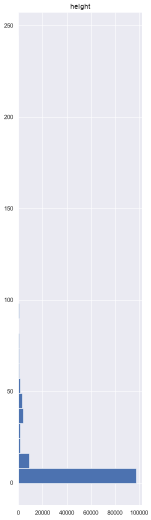

In [9]:
MapExplorer(b_gdf2, bp_gdf2).build_configurable(["height"], title="Buildings with height assigned")

## TODO: Building parts -> clean height envelopes

In [10]:
# for now just merge bpart into buildings

In [11]:
from src.map_processing.code.buildings import resolve_building_envelope

envelope_gdf = resolve_building_envelope(
    b_gdf2,
    bp_gdf2,
    remove_elevated_parts=True,
    min_height_fraction_threshold=0.9,
    dissolve=True,
    min_area=0.01,
)

In [12]:
envelope_gdf["num_floors"] = 0 # needed for rendering

In [13]:
MapExplorer(envelope_gdf).build_configurable(
    ["height"], title="Buildings height evelope", show_histogram=False
)

0    290.0
1    283.0
2    280.0
3    280.0
4    280.0
Name: height_calc, dtype: float64


In [14]:
b_gdf_combined = envelope_gdf.to_crs(4326)

In [15]:
# b_gdf_combined = pd.concat(
#     [
#         b_gdf2[["height", "geometry"]].reset_index(drop=True),
#         bp_gdf2[["height", "geometry"]].reset_index(drop=True),
#     ]
# )
# b_gdf_combined = b_gdf_combined.to_crs("4326")

# Export

In [16]:
out_fpath = os.path.join(
    "./out/",
    "buildings.geojson",
)

if ALLOW_EXPORT:
    print("EXPORTING...")
    b_gdf_combined.to_file(out_fpath, driver="GeoJSON") 